# Tahap 8 — Optimasi Inventori

Notebook ini membangun ulang kontrak D8 dalam format notebook mandiri dari
artefak prediksi Tahap 6–7 yang sudah diverifikasi.

In [1]:
from __future__ import annotations
from pathlib import Path
import json
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
CFG = yaml.safe_load((ROOT / "config.yaml").read_text(encoding="utf-8"))
SEED = int(CFG["seed"])
np.random.seed(SEED)

def rp(*parts: str) -> Path:
    """Resolve a repo-relative path (parts are path fragments under the repo root)."""
    return ROOT.joinpath(*parts)

BRAND_COLORS = {"OPPO": "#0072B2", "Realme": "#D55E00", "Samsung": "#009E73",
                "Vivo": "#CC79A7", "Xiaomi": "#E69F00"}
ALGO_COLORS = {"SARIMAX": "#0072B2", "RF": "#D55E00", "LSTM": "#009E73"}
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (9, 4.5),
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 12})

D8 menetapkan bahwa safety stock harus dihitung dari **simpangan baku galat
ramalan one-step-ahead** hasil rezim walk-forward D9, bukan dari simpangan
baku permintaan historis. Karena itu rumus utamanya adalah
`SS = z · σ · √L`, dengan `σ` diambil dari residual uji per deret gerai×merek.

Rumus turunan yang dipakai tetap persis seperti kontrak sumber:
`ROP = μ · L + SS` dan `OUL = ROP + μ · R`, dengan konfigurasi notebook ini
`service_level = 0.95`, `lead_time_weeks = 2`, `review_period_weeks = 1`,
dan `holding_cost = 0.02`.

Pemenang Tahap 7 dibaca ulang dari `metrics_summary.csv`; hasilnya harus tetap
`RF(gt)`. Setelah itu notebook mensimulasikan kebijakan periodic-review
order-up-to lost-sales untuk varian terbaik tiap algoritma, lalu menghitung
sensitivitas pada grid 3×3 untuk service level `0.90/0.95/0.99` dan holding
cost `0.01/0.02/0.05`.

In [2]:
import logging
from IPython.display import display
from matplotlib.colors import to_hex
from matplotlib.patches import Patch
from scipy import stats

logger = logging.getLogger("notebook.08_inventory")

ALGOS = ["sarimax", "rf", "lstm"]
VARIANTS = ["baseline", "gt"]
ALGO_LABEL = {"sarimax": "SARIMAX", "rf": "RF", "lstm": "LSTM"}
SERVICE_LEVELS = (0.90, 0.95, 0.99)
HOLDING_COSTS = (0.01, 0.02, 0.05)
RESULTS_DIR = rp(*Path(CFG["paths"]["results"]).parts)
FIGURE_AUDIT: list[dict] = []


def cfg_path(cfg: dict, key: str) -> Path:
    """Resolve a configured relative path under the notebook repo root."""
    return rp(*Path(cfg["paths"][key]).parts)


def _load_predictions(results_dir: str | Path) -> dict[tuple[str, str], pd.DataFrame]:
    """Inline the metrics.py prediction loader for the six main model outputs."""
    results_dir = Path(results_dir)
    out: dict[tuple[str, str], pd.DataFrame] = {}
    for algo in ALGOS:
        for variant in VARIANTS:
            path = results_dir / f"predictions_{algo}_{variant}.parquet"
            if path.exists():
                out[(algo, variant)] = pd.read_parquet(path)
            else:
                logger.warning("Prediksi hilang: %s", path)
    return out


def z_from_service_level(service_level: float) -> float:
    """Faktor keamanan z = Φ⁻¹(service_level) (kuantil normal baku)."""
    return float(stats.norm.ppf(service_level))


def forecast_error_sigma(y_true, y_pred) -> float:
    """σ galat peramalan one-step (D9) = simpangan baku sampel residual (ddof=1)."""
    resid = np.asarray(y_true, float) - np.asarray(y_pred, float)
    if resid.size < 2:
        return 0.0
    return float(np.std(resid, ddof=1))


def safety_stock(sigma: float, z: float, lead_time_weeks: float) -> float:
    """SS = z · σ_galat · sqrt(L)."""
    return float(z * sigma * np.sqrt(lead_time_weeks))


def reorder_point(mean_weekly_demand: float, lead_time_weeks: float, ss: float) -> float:
    """ROP = μ_minggu · L + SS."""
    return float(mean_weekly_demand * lead_time_weeks + ss)


def order_up_to_level(rop: float, mean_weekly_demand: float, review_period_weeks: float) -> float:
    """OUL = ROP + μ_minggu · R."""
    return float(rop + mean_weekly_demand * review_period_weeks)


def series_params(y_true, y_pred, z: float, lead_time_weeks: float, review_period_weeks: float) -> dict:
    """Inventory parameters for one store-brand series."""
    sigma = forecast_error_sigma(y_true, y_pred)
    mu = float(np.mean(np.asarray(y_true, float)))
    ss = safety_stock(sigma, z, lead_time_weeks)
    rop = reorder_point(mu, lead_time_weeks, ss)
    oul = order_up_to_level(rop, mu, review_period_weeks)
    return {
        "sigma_error": sigma,
        "mean_weekly_demand": mu,
        "safety_stock": ss,
        "reorder_point": rop,
        "order_up_to_level": oul,
    }


def simulate_base_stock(
    demand,
    S: float,
    lead_time_weeks: int,
    review_period_weeks: int = 1,
    init_inventory: float | None = None,
) -> dict:
    """Simulate a lost-sales periodic-review order-up-to policy."""
    d = np.asarray(demand, float)
    T = d.size
    L = int(lead_time_weeks)
    R = max(int(review_period_weeks), 1)
    on_hand = float(S if init_inventory is None else init_inventory)
    arrivals: dict[int, float] = {}
    outstanding = 0.0

    stockout_weeks = 0
    shortage_units = 0.0
    holding_unit_weeks = 0.0

    for t in range(T):
        if t in arrivals:
            recv = arrivals.pop(t)
            on_hand += recv
            outstanding -= recv

        sales = min(on_hand, d[t])
        shortage = d[t] - sales
        on_hand -= sales

        if shortage > 1e-9:
            stockout_weeks += 1
            shortage_units += shortage

        holding_unit_weeks += on_hand

        if t % R == 0:
            inventory_position = on_hand + outstanding
            order = max(0.0, S - inventory_position)
            if order > 1e-9:
                arrivals[t + L] = arrivals.get(t + L, 0.0) + order
                outstanding += order

    demand_total = float(d.sum())
    fill_rate = 1.0 if demand_total <= 0 else (demand_total - shortage_units) / demand_total
    return {
        "n_weeks": T,
        "stockout_weeks": stockout_weeks,
        "shortage_units": float(shortage_units),
        "demand_total": demand_total,
        "holding_unit_weeks": float(holding_unit_weeks),
        "fill_rate": float(fill_rate),
        "service_level_ach": float(1.0 - stockout_weeks / T) if T else float("nan"),
    }


def inventory_params_table(
    preds: pd.DataFrame,
    service_level: float,
    lead_time_weeks: float,
    review_period_weeks: float,
) -> pd.DataFrame:
    """Per-series inventory parameters for the final winner."""
    z = z_from_service_level(service_level)
    rows = []
    for (store, brand), g in preds.groupby(["store", "brand"]):
        g = g.sort_values("week_start")
        p = series_params(
            g["y_true"].to_numpy(),
            g["y_pred"].to_numpy(),
            z,
            lead_time_weeks,
            review_period_weeks,
        )
        rows.append({"store": store, "brand": brand, "z": z, **p})
    return pd.DataFrame(rows).sort_values(["store", "brand"]).reset_index(drop=True)


def _simulate_series(g: pd.DataFrame, z: float, lead_time_weeks: float, review_period_weeks: float) -> dict:
    """Combine one-series inventory parameter calculation and base-stock simulation."""
    g = g.sort_values("week_start")
    yt = g["y_true"].to_numpy()
    yp = g["y_pred"].to_numpy()
    params = series_params(yt, yp, z, lead_time_weeks, review_period_weeks)
    sim = simulate_base_stock(
        yt,
        S=params["order_up_to_level"],
        lead_time_weeks=int(lead_time_weeks),
        review_period_weeks=int(review_period_weeks),
    )
    return {**params, **sim}


def cost_impact_table(
    preds_by_algo: dict[str, pd.DataFrame],
    service_level: float,
    lead_time_weeks: float,
    review_period_weeks: float,
    holding_cost: float,
) -> pd.DataFrame:
    """Aggregate simulated inventory cost impact for each algorithm."""
    z = z_from_service_level(service_level)
    rows = []
    for algo, preds in preds_by_algo.items():
        ss_list, hold_uw, stockouts, shortage, dem_tot, n_weeks = [], 0.0, 0, 0.0, 0.0, 0
        for _, g in preds.groupby(["store", "brand"]):
            result = _simulate_series(g, z, lead_time_weeks, review_period_weeks)
            ss_list.append(result["safety_stock"])
            hold_uw += result["holding_unit_weeks"]
            stockouts += result["stockout_weeks"]
            shortage += result["shortage_units"]
            dem_tot += result["demand_total"]
            n_weeks += result["n_weeks"]
        fill = 1.0 if dem_tot <= 0 else (dem_tot - shortage) / dem_tot
        rows.append({
            "algo": algo,
            "safety_stock_mean": float(np.mean(ss_list)),
            "holding_unit_weeks": float(hold_uw),
            "holding_cost_total": float(holding_cost * hold_uw),
            "stockout_weeks": int(stockouts),
            "shortage_units": float(shortage),
            "fill_rate": float(fill),
            "service_level_ach": float(1.0 - stockouts / n_weeks) if n_weeks else float("nan"),
        })
    return pd.DataFrame(rows)


def sensitivity_table(
    best_preds: pd.DataFrame,
    lead_time_weeks: float,
    review_period_weeks: float,
    holding_cost_base: float,
    service_levels=SERVICE_LEVELS,
    holding_costs=HOLDING_COSTS,
) -> pd.DataFrame:
    """Sensitivity grid for service level and holding cost around the D8 baseline."""
    _ = holding_cost_base
    rows = []
    for sl in service_levels:
        params = inventory_params_table(best_preds, sl, lead_time_weeks, review_period_weeks)
        z = z_from_service_level(sl)
        hold_uw, stockouts, shortage, dem_tot, n_weeks = 0.0, 0, 0.0, 0.0, 0
        for _, g in best_preds.groupby(["store", "brand"]):
            result = _simulate_series(g, z, lead_time_weeks, review_period_weeks)
            hold_uw += result["holding_unit_weeks"]
            stockouts += result["stockout_weeks"]
            shortage += result["shortage_units"]
            dem_tot += result["demand_total"]
            n_weeks += result["n_weeks"]
        fill = 1.0 if dem_tot <= 0 else (dem_tot - shortage) / dem_tot
        for hc in holding_costs:
            rows.append({
                "service_level": sl,
                "holding_cost": hc,
                "safety_stock_mean": float(params["safety_stock"].mean()),
                "order_up_to_level_mean": float(params["order_up_to_level"].mean()),
                "holding_cost_total": float(hc * hold_uw),
                "stockout_weeks": int(stockouts),
                "fill_rate": float(fill),
            })
    return pd.DataFrame(rows)


def _best_variant_per_algo(results_dir: str | Path) -> dict[str, str]:
    """Read Task 7 summary and keep the best baseline/gt variant for each algorithm."""
    path = Path(results_dir) / "metrics_summary.csv"
    if not path.exists():
        return {algo: "gt" for algo in ALGO_LABEL}
    summary = pd.read_csv(path)
    summary = summary[summary["variant"].isin(["baseline", "gt"])]
    best: dict[str, str] = {}
    for algo in ALGO_LABEL:
        sub = summary[summary["algo"] == algo]
        if len(sub):
            best[algo] = str(sub.loc[sub["MAE_mean"].idxmin(), "variant"])
    return best


def _final_winner_key(results_dir: str | Path, best_per_algo: dict[str, str]) -> tuple[str, str]:
    """Read Task 7 summary and select the final best baseline/gt model."""
    path = Path(results_dir) / "metrics_summary.csv"
    if not path.exists():
        return ("rf", best_per_algo.get("rf", "gt"))
    summary = pd.read_csv(path)
    summary = summary[summary["variant"].isin(["baseline", "gt"])]
    row = summary.loc[summary["MAE_mean"].idxmin()]
    return (str(row["algo"]), str(row["variant"]))


def run_inventory(cfg: dict, save: bool = True) -> dict:
    """Compute D8 winner parameters, cost impact, and sensitivity tables."""
    results_dir = cfg_path(cfg, "results")
    preds = _load_predictions(results_dir)
    if not preds:
        raise FileNotFoundError(f"Tak ada file prediksi di {results_dir}. Jalankan Tahap 6–7 dulu.")

    lead_time_weeks = float(cfg["lead_time_weeks"])
    review_period_weeks = float(cfg["review_period_weeks"])
    service_level = float(cfg["service_level"])
    holding_cost = float(cfg["holding_cost"])

    best_per_algo = _best_variant_per_algo(results_dir)
    winner_algo, winner_variant = _final_winner_key(results_dir, best_per_algo)
    best_preds = preds[(winner_algo, winner_variant)]

    params = inventory_params_table(best_preds, service_level, lead_time_weeks, review_period_weeks)
    params.insert(0, "model", f"{ALGO_LABEL.get(winner_algo, winner_algo)}({winner_variant})")

    preds_by_algo = {
        ALGO_LABEL[algo]: preds[(algo, best_per_algo.get(algo, "gt"))]
        for algo in ALGO_LABEL
        if (algo, best_per_algo.get(algo, "gt")) in preds
    }
    cost = cost_impact_table(preds_by_algo, service_level, lead_time_weeks, review_period_weeks, holding_cost)
    label_to_algo = {label: algo for algo, label in ALGO_LABEL.items()}
    cost.insert(1, "variant", [best_per_algo.get(label_to_algo[label], "gt") for label in cost["algo"]])

    sensitivity = sensitivity_table(best_preds, lead_time_weeks, review_period_weeks, holding_cost)

    if save:
        results_dir.mkdir(parents=True, exist_ok=True)
        params.to_csv(results_dir / "inventory_params.csv", index=False)
        cost.to_csv(results_dir / "cost_impact.csv", index=False)
        sensitivity.to_csv(results_dir / "inventory_sensitivity.csv", index=False)

    return {
        "winner": (winner_algo, winner_variant),
        "params": params,
        "cost_impact": cost,
        "sensitivity": sensitivity,
    }


def plot_cost_impact(cost_df: pd.DataFrame, display_inline: bool = True) -> dict:
    """Render the required inline inventory cost-impact bar chart."""
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    colors = [ALGO_COLORS[algo] for algo in cost_df["algo"]]
    bars = ax.bar(cost_df["algo"], cost_df["holding_cost_total"], color=colors, edgecolor="black", linewidth=0.6)
    ax.set_title("Dampak biaya simpan inventori per algoritma")
    ax.set_xlabel("Algoritma")
    ax.set_ylabel("Total biaya simpan (fraksi harga-unit)")
    ax.legend(
        handles=[Patch(facecolor=ALGO_COLORS[algo], edgecolor="black", label=algo) for algo in cost_df["algo"]],
        title="Algoritma",
        loc="upper right",
    )
    fig.tight_layout()

    audit = {
        "bar_count": len(bars),
        "bar_heights": [float(bar.get_height()) for bar in bars],
        "bar_colors": [to_hex(bar.get_facecolor(), keep_alpha=False).lower() for bar in bars],
        "title": ax.get_title(),
        "xlabel": ax.get_xlabel(),
        "ylabel": ax.get_ylabel(),
        "legend_visible": bool(ax.get_legend() is not None and ax.get_legend().get_visible()),
        "displayed_inline": bool(display_inline),
    }
    FIGURE_AUDIT.append(audit)
    if display_inline:
        display(fig)
    plt.close(fig)
    return audit

## Memilih pemenang Tahap 7

Notebook ini membaca ulang `metrics_summary.csv` agar keputusan model terbaik
tetap berasal dari artefak Tahap 7, bukan dari asumsi baru di Tahap 8.

In [3]:
metrics_summary = pd.read_csv(RESULTS_DIR / "metrics_summary.csv")
model_rows = metrics_summary[metrics_summary["variant"].isin(["baseline", "gt"])].copy()
winner_row = model_rows.loc[model_rows["MAE_mean"].idxmin()]
winner_view = model_rows[["algo", "variant", "MAE_mean", "MASE_mean", "is_best"]].copy()
display(winner_view)
print(
    "Pemenang Tahap 7 yang dibawa ke D8:",
    f"{ALGO_LABEL[str(winner_row['algo'])]}({winner_row['variant']})",
)

,algo,variant,MAE_mean,MASE_mean,is_best
0,sarimax,baseline,1.641734,0.884088,False
1,sarimax,gt,1.595297,0.863637,False
2,rf,baseline,1.406645,0.763366,False
3,rf,gt,1.399524,0.761813,True
4,lstm,baseline,1.572478,0.865263,False
5,lstm,gt,1.540039,0.843473,False


Pemenang Tahap 7 yang dibawa ke D8: RF(gt)


## Menjalankan optimasi inventori dan simulasi lost-sales

Jalur ini menjalankan `run_inventory(CFG, save=True)` untuk:

- menghitung tabel parameter inventori 20 deret untuk model pemenang `RF(gt)`,
- mensimulasikan periodic-review order-up-to policy untuk tiga algoritma,
- menulis ulang tiga CSV deterministik Tahap 8,
- menampilkan tabel hasil dan grafik biaya simpan inline.

,model,store,brand,z,sigma_error,mean_weekly_demand,safety_stock,reorder_point,order_up_to_level
0,RF(gt),Toko_A,OPPO,1.644854,2.061087,2.486486,4.794447,9.767420,12.253906
1,RF(gt),Toko_A,Realme,1.644854,1.777213,3.054054,4.134108,10.242216,13.296270
2,RF(gt),Toko_A,Samsung,1.644854,1.866558,2.108108,4.341938,8.558154,10.666263
3,RF(gt),Toko_A,Vivo,1.644854,1.815291,1.837838,4.222683,7.898358,9.736196
4,RF(gt),Toko_A,Xiaomi,1.644854,2.410780,3.486486,5.607894,12.580867,16.067353
5,RF(gt),Toko_B,OPPO,1.644854,1.672221,2.351351,3.889878,8.592581,10.943932
6,RF(gt),Toko_B,Realme,1.644854,2.102199,3.270270,4.890081,11.430621,14.700892
7,RF(gt),Toko_B,Samsung,1.644854,1.434028,2.027027,3.335799,7.389853,9.416880
8,RF(gt),Toko_B,Vivo,1.644854,1.435368,1.729730,3.338916,6.798376,8.528105
9,RF(gt),Toko_B,Xiaomi,1.644854,2.034642,2.540541,4.732933,9.814014,12.354554


,algo,variant,safety_stock_mean,holding_unit_weeks,holding_cost_total,stockout_weeks,shortage_units,fill_rate,service_level_ach
0,SARIMAX,gt,4.352635,4781.198575,95.623972,13,6.624234,0.995687,0.982432
1,RF,gt,3.967087,4504.277198,90.085544,13,10.816227,0.992958,0.982432
2,LSTM,gt,4.023423,4544.779237,90.895585,13,10.222975,0.993344,0.982432


,service_level,holding_cost,safety_stock_mean,order_up_to_level_mean,holding_cost_total,stockout_weeks,fill_rate
0,0.90,0.01,3.090869,9.317896,38.804177,18,0.984969
1,0.90,0.02,3.090869,9.317896,77.608355,18,0.984969
2,0.90,0.05,3.090869,9.317896,194.020887,18,0.984969
3,0.95,0.01,3.967087,10.194115,45.042772,13,0.992958
4,0.95,0.02,3.967087,10.194115,90.085544,13,0.992958
5,0.95,0.05,3.967087,10.194115,225.213860,13,0.992958
6,0.99,0.01,5.610728,11.837755,56.989438,1,0.999998
7,0.99,0.02,5.610728,11.837755,113.978876,1,0.999998
8,0.99,0.05,5.610728,11.837755,284.947191,1,0.999998


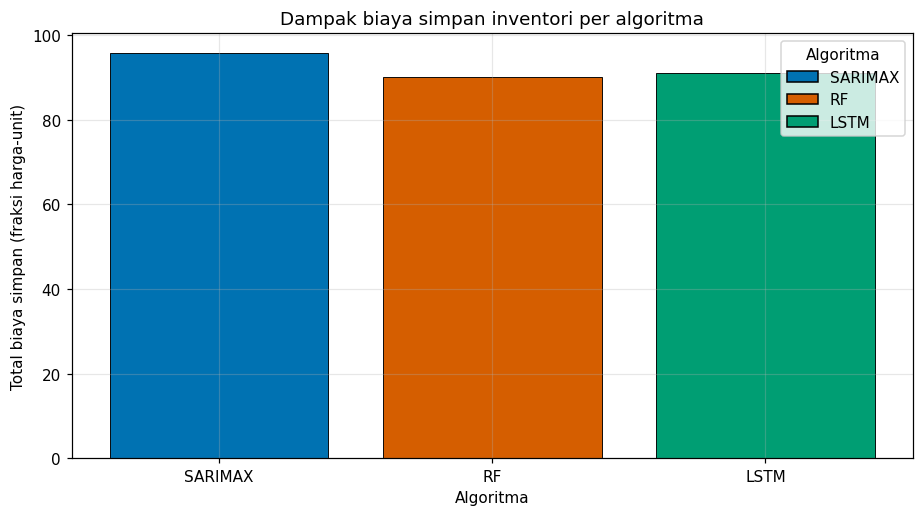

Winner key: ('rf', 'gt')
Variasi terbaik per algoritma: {'sarimax': 'gt', 'rf': 'gt', 'lstm': 'gt'}


In [4]:
inventory_result = run_inventory(CFG, save=True)
display(inventory_result["params"])
display(inventory_result["cost_impact"])
display(inventory_result["sensitivity"])
cost_chart_audit = plot_cost_impact(inventory_result["cost_impact"], display_inline=True)

print("Winner key:", inventory_result["winner"])
print("Variasi terbaik per algoritma:", _best_variant_per_algo(RESULTS_DIR))

In [5]:
EXPECTED_RESULT_KEYS = {"winner", "params", "cost_impact", "sensitivity"}
assert set(inventory_result.keys()) == EXPECTED_RESULT_KEYS
assert inventory_result["winner"] == ("rf", "gt")

expected_param_columns = [
    "model", "store", "brand", "z", "sigma_error", "mean_weekly_demand",
    "safety_stock", "reorder_point", "order_up_to_level",
]
expected_cost_columns = [
    "algo", "variant", "safety_stock_mean", "holding_unit_weeks", "holding_cost_total",
    "stockout_weeks", "shortage_units", "fill_rate", "service_level_ach",
]
expected_sensitivity_columns = [
    "service_level", "holding_cost", "safety_stock_mean", "order_up_to_level_mean",
    "holding_cost_total", "stockout_weeks", "fill_rate",
]

reloaded_params = pd.read_csv(rp("reports", "results", "inventory_params.csv"))
reloaded_cost = pd.read_csv(rp("reports", "results", "cost_impact.csv"))
reloaded_sensitivity = pd.read_csv(rp("reports", "results", "inventory_sensitivity.csv"))

pd.testing.assert_frame_equal(
    inventory_result["params"],
    reloaded_params,
    check_dtype=False,
    atol=1e-12,
    rtol=1e-12,
)
pd.testing.assert_frame_equal(
    inventory_result["cost_impact"],
    reloaded_cost,
    check_dtype=False,
    atol=1e-12,
    rtol=1e-12,
)
pd.testing.assert_frame_equal(
    inventory_result["sensitivity"],
    reloaded_sensitivity,
    check_dtype=False,
    atol=1e-12,
    rtol=1e-12,
)

assert reloaded_params.shape == (20, 9)
assert reloaded_cost.shape == (3, 9)
assert reloaded_sensitivity.shape == (9, 7)
assert reloaded_params.columns.tolist() == expected_param_columns
assert reloaded_cost.columns.tolist() == expected_cost_columns
assert reloaded_sensitivity.columns.tolist() == expected_sensitivity_columns

expected_z = z_from_service_level(0.95)
assert np.allclose(reloaded_params["z"], expected_z)
assert np.allclose(reloaded_params["safety_stock"], reloaded_params["z"] * reloaded_params["sigma_error"] * np.sqrt(2.0))
assert np.allclose(reloaded_params["reorder_point"], reloaded_params["mean_weekly_demand"] * 2.0 + reloaded_params["safety_stock"])
assert np.allclose(reloaded_params["order_up_to_level"], reloaded_params["reorder_point"] + reloaded_params["mean_weekly_demand"] * 1.0)

assert (reloaded_params["model"] == "RF(gt)").all()
assert (reloaded_params[["sigma_error", "mean_weekly_demand", "safety_stock", "reorder_point", "order_up_to_level"]] >= 0).all().all()

assert set(reloaded_cost["algo"]) == {"SARIMAX", "RF", "LSTM"}
assert set(reloaded_cost["variant"]) == {"gt"}
assert (reloaded_cost[["safety_stock_mean", "holding_unit_weeks", "holding_cost_total", "stockout_weeks", "shortage_units"]] >= 0).all().all()
assert reloaded_cost["fill_rate"].between(0, 1).all()
assert reloaded_cost["service_level_ach"].between(0, 1).all()
assert np.allclose(reloaded_cost["holding_cost_total"], 0.02 * reloaded_cost["holding_unit_weeks"])

expected_grid = {(sl, hc) for sl in SERVICE_LEVELS for hc in HOLDING_COSTS}
actual_grid = {(float(sl), float(hc)) for sl, hc in zip(reloaded_sensitivity["service_level"], reloaded_sensitivity["holding_cost"])}
assert actual_grid == expected_grid
assert (reloaded_sensitivity[["safety_stock_mean", "order_up_to_level_mean", "holding_cost_total", "stockout_weeks"]] >= 0).all().all()
assert reloaded_sensitivity["fill_rate"].between(0, 1).all()

for service_level, group in reloaded_sensitivity.groupby("service_level"):
    g = group.sort_values("holding_cost").reset_index(drop=True)
    assert g["safety_stock_mean"].nunique() == 1, service_level
    assert g["order_up_to_level_mean"].nunique() == 1, service_level
    assert g["stockout_weeks"].nunique() == 1, service_level
    assert g["fill_rate"].nunique() == 1, service_level
    scaled_holding = g["holding_cost_total"] / g["holding_cost"]
    assert np.allclose(scaled_holding, scaled_holding.iloc[0]), service_level

ss_by_service = (
    reloaded_sensitivity[["service_level", "safety_stock_mean"]]
    .drop_duplicates()
    .sort_values("service_level")
    .reset_index(drop=True)
)
assert ss_by_service["safety_stock_mean"].is_monotonic_increasing

assert forecast_error_sigma([1, 2, 3], [1, 1, 1]) == 1.0
zero_sim = simulate_base_stock([0, 0, 0, 0], S=5, lead_time_weeks=2, review_period_weeks=1)
assert zero_sim == {
    "n_weeks": 4,
    "stockout_weeks": 0,
    "shortage_units": 0.0,
    "demand_total": 0.0,
    "holding_unit_weeks": 20.0,
    "fill_rate": 1.0,
    "service_level_ach": 1.0,
}

assert FIGURE_AUDIT, "Tidak ada audit figur biaya inventori."
inline_figures = [item for item in FIGURE_AUDIT if item["displayed_inline"]]
assert inline_figures, "Tidak ada figur biaya inventori yang ditampilkan inline."
assert any(
    item["bar_count"] == 3
    and all(height > 0 for height in item["bar_heights"])
    and item["legend_visible"]
    and item["title"] == "Dampak biaya simpan inventori per algoritma"
    and item["xlabel"] == "Algoritma"
    and item["ylabel"] == "Total biaya simpan (fraksi harga-unit)"
    and item["bar_colors"] == [ALGO_COLORS["SARIMAX"].lower(), ALGO_COLORS["RF"].lower(), ALGO_COLORS["LSTM"].lower()]
    for item in inline_figures
), inline_figures

import ast

source_text = rp("notebooks", "08_inventory.py").read_text(encoding="utf-8")
source_for_ast = "\n".join(line for line in source_text.splitlines() if not line.lstrip().startswith("%"))
module_ast = ast.parse(source_for_ast)
for node in ast.walk(module_ast):
    if isinstance(node, ast.Import):
        assert all(alias.name != "src" and not alias.name.startswith("src.") for alias in node.names)
    if isinstance(node, ast.ImportFrom):
        assert node.module is None or (node.module != "src" and not node.module.startswith("src."))
    if isinstance(node, ast.Call) and isinstance(node.func, ast.Attribute):
        if isinstance(node.func.value, ast.Name) and node.func.value.id == "matplotlib" and node.func.attr == "use":
            first_arg = node.args[0] if node.args else None
            if isinstance(first_arg, ast.Constant) and isinstance(first_arg.value, str):
                assert first_arg.value != "Agg"

string_literals = [node.value for node in ast.walk(module_ast) if isinstance(node, ast.Constant) and isinstance(node.value, str)]
assert not any(len(value) >= 3 and value[1:3] == ":\\" for value in string_literals)

params = pd.read_csv(rp("reports", "results", "inventory_params.csv"))
cost = pd.read_csv(rp("reports", "results", "cost_impact.csv"))
assert len(params) == 20
assert {"safety_stock", "reorder_point", "order_up_to_level"}.issubset(params.columns)
assert (params["safety_stock"] >= 0).all()
assert params["model"].str.startswith("RF").all()          # pemenang Tahap 7 = RF·gt
assert set(cost["algo"]) == {"SARIMAX", "RF", "LSTM"} and len(cost) == 3
assert cost["fill_rate"].between(0, 1).all()
print("✅ Tahap 8: 20 deret params (SS≥0), pemenang RF, dampak biaya 3 algoritma")

✅ Tahap 8: 20 deret params (SS≥0), pemenang RF, dampak biaya 3 algoritma
